# hERG մոդելի սխալների վերլուծություն

Այս notebook-ում կտեսնենք՝ **քանի միացություն է մոդելը ճիշտ ճանաչել, ինչ սխալներ է արել և ինչ մոլեկուլների վրա է սխալվել**։ Գործարկիր **Run All** կամ բջիջները հերթով՝ **Shift + Enter**։

Օգտագործում ենք training բաժնով ուսուցանված ընտրված մոդելի **պահպանված test կանխատեսումները**, որոնք հաշվարկվել են մինչև ամբողջ dataset-ով վերաուսուցումը։ Notebook-ը մոդել չի ուսուցանում և demo մոդելի նոր կանխատեսումներով չի փոխարինում test արդյունքները։

Սա արդեն դիտարկված test set-ի նկարագրական վերլուծություն է։ Դրա հիման վրա մոդել փոխելու դեպքում նոր անկախ գնահատում է անհրաժեշտ։

**Պահպանված նախորդ մոդելը․** առկայության դեպքում այս notebook-ը կարդում է `herg_precision_baseline.joblib`-ը՝ նախորդ համեմատությունը պահպանելու համար։ Նոր որոնումը՝ `05_model_improvement.ipynb`-ում։

## 1. Բեռնում և արդյունքների ստուգում

Եթե պահպանված մոդելը հին է և test կանխատեսումներ չունի, նախ գործարկիր `make train` նախագծի պանակից։ Ստուգում ենք, որ dataset-ը նույնն է, test տողերն ու training տողերը չեն խաչվում, և պահպանված չափանիշները վերահաշվարկվում են նույն արդյունքներով։

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from rdkit import Chem
from rdkit.Chem import Draw
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix,
    precision_recall_curve, average_precision_score, roc_curve, roc_auc_score)

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src.molecules import calculate_descriptors, scaffold_key
from src.modeling import _classification_metrics

BASELINE_PATH = ROOT / "models/herg_precision_baseline.joblib"
MODEL_PATH = BASELINE_PATH if BASELINE_PATH.is_file() else ROOT / "models/herg_model.joblib"
DATA_PATH = ROOT / "data/raw/herg_karim.csv"
if not MODEL_PATH.is_file():
    raise FileNotFoundError("Run make train first to create the evaluation artifact.")
artifact = joblib.load(MODEL_PATH)  # Load only your own trusted local artifact.
if "test_predictions" not in artifact:
    raise ValueError("Saved predictions are missing. Run make train, then Run All again.")
if sha256(DATA_PATH.read_bytes()).hexdigest() != artifact["dataset_sha256"]:
    raise ValueError("The dataset has changed since training. Run make train again.")
results = artifact["test_predictions"].copy()
dataset = pd.read_csv(DATA_PATH)
train_rows = np.asarray(artifact["train_indices"])
assert len(results) == artifact["test_size"]
assert results.row_index.is_unique
assert set(results.row_index).isdisjoint(train_rows)
assert len(train_rows) + len(results) == len(dataset)
train_scaffolds = set(dataset.iloc[train_rows].smiles.map(scaffold_key))
assert train_scaffolds.isdisjoint(results.scaffold)
recomputed = _classification_metrics(results.label.to_numpy(),
    results.prediction.to_numpy(), results.score.to_numpy())
for metric, value in recomputed.items():
    assert np.isclose(value, artifact["test_metrics"][metric]), metric
assert results.score.between(0, 1).all()
results["outcome"] = np.select([
    (results.label == 0) & (results.prediction == 0),
    (results.label == 0) & (results.prediction == 1),
    (results.label == 1) & (results.prediction == 0),
    (results.label == 1) & (results.prediction == 1),
], ["TN", "FP", "FN", "TP"], default="Unknown")
results["correct"] = results.label.eq(results.prediction)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
COLORS = {0: "#3677ad", 1: "#d57928"}
NAMES = {0: "Non-inhibitor (0)", 1: "Inhibitor (1)"}
display(pd.Series({"Model": artifact["model_name"], "Training rows": len(train_rows),
    "Test rows": len(results), "Random seed": artifact["random_state"],
    "Scaffold overlap": 0}, name="Evaluation").to_frame())
display(pd.Series(recomputed, name="Test metric").to_frame().round(4))

,Evaluation
Model,Random forest
Training rows,10765
Test rows,2680
Random seed,42
Scaffold overlap,0


,Test metric
auprc,0.8926
roc_auc,0.8858
balanced_accuracy,0.8124
f1,0.8037
mcc,0.6272


## 2. Confusion matrix՝ ճիշտ և սխալ կանխատեսումները

Տողը dataset-ի իրական պիտակն է, սյունակը՝ կանխատեսումը։

- **TN** — non-inhibitor-ը ճիշտ ճանաչված է։
- **FP** — non-inhibitor-ը սխալ ճանաչված է որպես inhibitor՝ կեղծ ահազանգ։
- **FN** — inhibitor-ը բաց է թողնված՝ կանխատեսված է non-inhibitor։
- **TP** — inhibitor-ը ճիշտ ճանաչված է։

Աջ նկարում յուրաքանչյուր տողը նորմավորված է առանձին․ երևում է տվյալ դասի որ տոկոսն է ճիշտ կամ սխալ ճանաչվել։ FN-ները հատկապես կարևոր են inhibitor բաց թողնելու տեսանկյունից, սակայն այս գնահատումը կլինիկական անվտանգության ապացույց չէ։

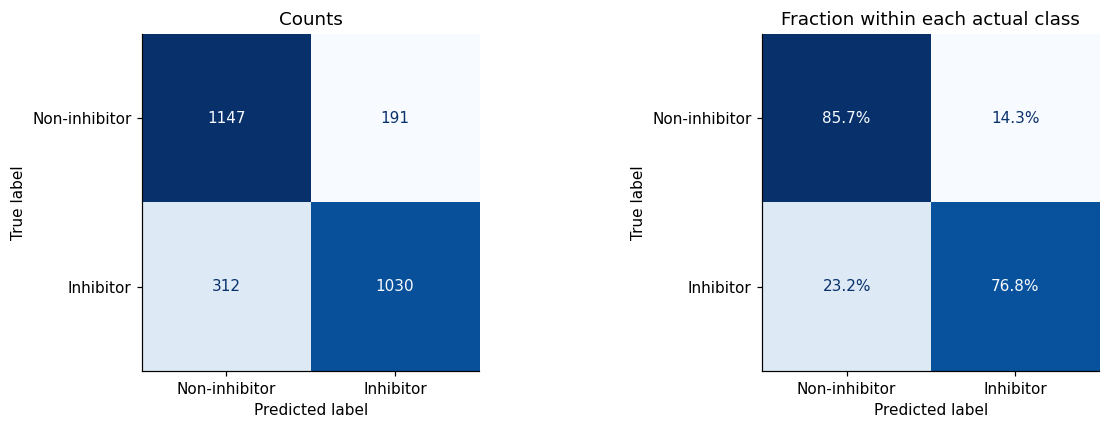

,Value
Correct classifications,2177.0000
False positives,191.0000
False negatives,312.0000
Precision: TP / (TP + FP),0.8436
Recall: TP / (TP + FN),0.7675
Specificity: TN / (TN + FP),0.8572


In [2]:
matrix = confusion_matrix(results.label, results.prediction, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, normalize, title in zip(axes, [None, "true"], ["Counts", "Fraction within each actual class"]):
    ConfusionMatrixDisplay.from_predictions(results.label, results.prediction,
        labels=[0, 1], display_labels=["Non-inhibitor", "Inhibitor"],
        normalize=normalize, cmap="Blues", ax=ax, colorbar=False,
        values_format="d" if normalize is None else ".1%")
    ax.set_title(title)
    ax.grid(False)
fig.tight_layout()
plt.show()
tn, fp, fn, tp = matrix.ravel()
assert [tn, fp, fn, tp] == [artifact["test_confusion"][k] for k in
    ["true_negatives", "false_positives", "false_negatives", "true_positives"]]
summary = pd.Series({
    "Correct classifications": int(tn + tp), "False positives": int(fp), "False negatives": int(fn),
    "Precision: TP / (TP + FP)": tp / (tp + fp) if tp + fp else np.nan,
    "Recall: TP / (TP + FN)": tp / (tp + fn) if tp + fn else np.nan,
    "Specificity: TN / (TN + FP)": tn / (tn + fp) if tn + fp else np.nan,
}, name="Value")
display(summary.to_frame().round(4))

**Ինչպես հասկանալ․** precision-ը ցույց է տալիս՝ inhibitor կանխատեսվածներից ինչ մասն է իրականում inhibitor։ Recall-ը ցույց է տալիս՝ իրական inhibitor-ներից ինչ մասն ենք գտել։ Երկուսն էլ պետք է նայել՝ սխալների տարբեր տեսակները հասկանալու համար։

### Ինչ է սա նշանակում թվերով

Այս պահպանված գործարկման **2,680** test միացություններից **2,177**-ը ճիշտ են դասակարգվել։

- Իրական inhibitor-ների **76.8%**-ը հայտնաբերվել է, **23.2%**-ը՝ բաց թողնվել։
- Իրական non-inhibitor-ների **14.3%**-ը սխալ ստացել է inhibitor կանխատեսում։
- Inhibitor կանխատեսվածներից **84.4%**-ի dataset-ի պիտակն իրականում 1 է։

«Բաց է թողնվել 23.2%» և «կանխատեսումների 84.4%-ը ճիշտ է» տարբեր հայտարարություններ են՝ տարբեր հայտարարներով։ Դրանք համապատասխանաբար recall-ի և precision-ի իմաստներն են։ Թվերը dataset-ը փոխելու դեպքում պետք է վերահաշվել։

## 3. Precision–recall և ROC կորերը

Մոդելը տալիս է inhibition score․ տարբեր որոշման շեմերը տալիս են precision–recall-ի տարբեր զույգեր։ Ձախ կորը ցույց է տալիս այդ փոխզիջումը։ Կետը պահպանված դասակարգումների աշխատանքային արդյունքն է։ Կետագիծը test set-ում inhibitor-ների բաժինն է՝ պատահական դասավորման հենանիշը։

Մեր կոդում «AUPRC»-ը հաշվարկվում է `average_precision_score`-ով՝ **Average Precision (AP)**․ սա կորի տակ տրապեցիաներով հաշվված մակերեսի հետ պարտադիր նույնը չէ։ Աջ ROC կորը ցույց է տալիս true positive rate-ը false positive rate-ի նկատմամբ։ Այստեղ test set-ով նոր շեմ չենք ընտրում։

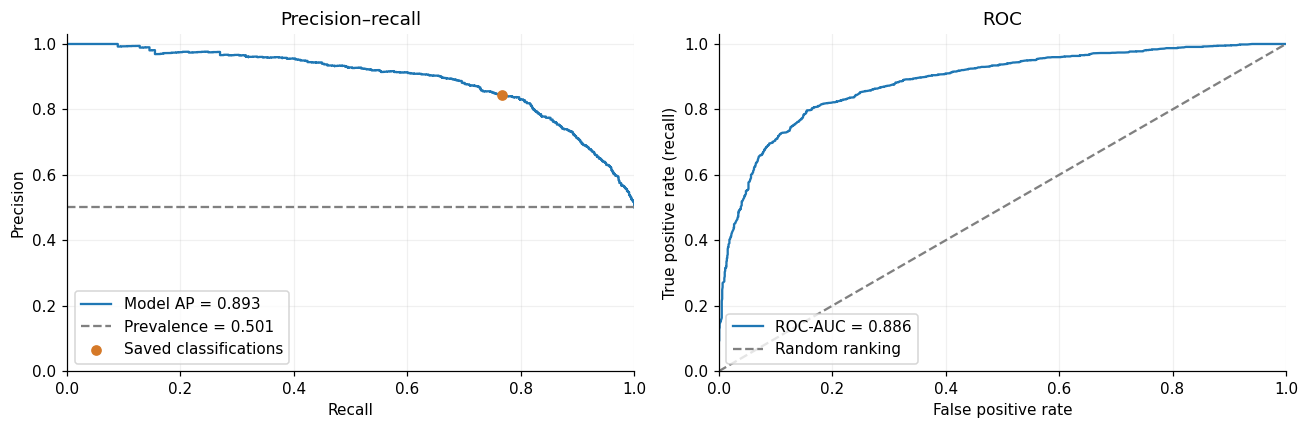

In [3]:
precision, recall, _ = precision_recall_curve(results.label, results.score)
fpr, tpr, _ = roc_curve(results.label, results.score)
ap = average_precision_score(results.label, results.score)
auc = roc_auc_score(results.label, results.score)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].step(recall, precision, where="post", label=f"Model AP = {ap:.3f}")
axes[0].axhline(results.label.mean(), linestyle="--", color="gray", label=f"Prevalence = {results.label.mean():.3f}")
axes[0].scatter(tp / (tp + fn), tp / (tp + fp), color="#d57928", zorder=3, label="Saved classifications")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision–recall", xlim=(0, 1), ylim=(0, 1.03))
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC", xlim=(0, 1), ylim=(0, 1.03))
for ax in axes:
    ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

## 4. Score-ների բաշխումը

Հորիզոնական առանցքը մոդելի score-ն է՝ 0-ից 1։ Գույնը իրական պիտակն է։ Աջում առանձին երևում են FP և FN սխալները։ 0.5 գիծը երկուական մոդելի սովորական որոշման սահմանն է, իսկ սխալների խմբերը վերցված են պահպանված `predict` արդյունքից։ Score-ը ստուգված կամ կալիբրացված անհատական ռիսկ չէ։

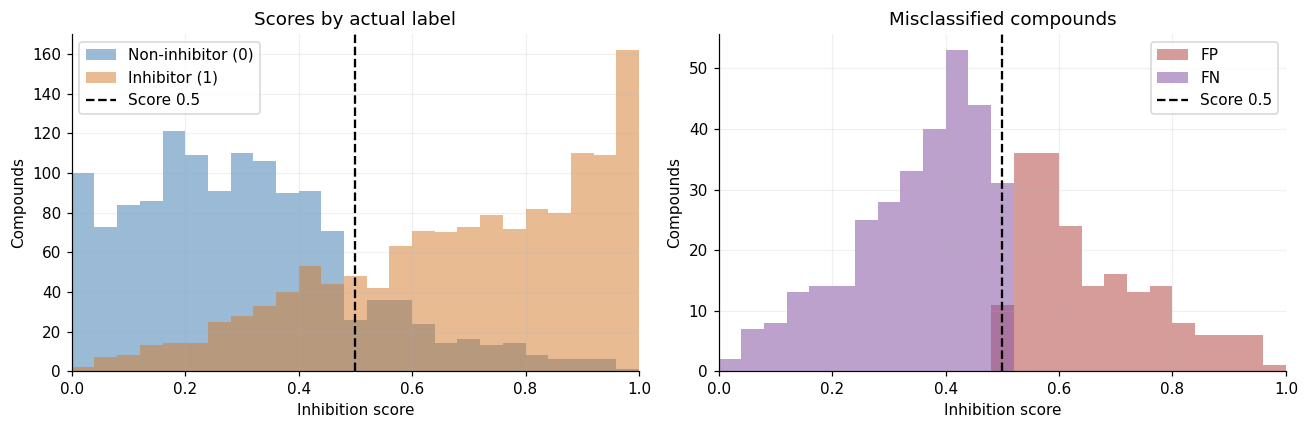

,count,min,median,max
outcome,,,,
FN,312,0.030,0.373,0.500
FP,191,0.503,0.617,0.973
TN,1147,0.000,0.240,0.500
TP,1030,0.503,0.813,1.000


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 26)
for label in [0, 1]:
    axes[0].hist(results.loc[results.label == label, "score"], bins=bins,
                 alpha=0.5, color=COLORS[label], label=NAMES[label])
for outcome, color in [("FP", "#b44c48"), ("FN", "#8655a4")]:
    axes[1].hist(results.loc[results.outcome == outcome, "score"], bins=bins,
                 alpha=0.55, color=color, label=outcome)
for ax, title in zip(axes, ["Scores by actual label", "Misclassified compounds"]):
    ax.axvline(0.5, linestyle="--", color="black", label="Score 0.5")
    ax.set(xlabel="Inhibition score", ylabel="Compounds", title=title, xlim=(0, 1))
    ax.legend()
fig.tight_layout()
plt.show()
display(results.groupby("outcome").score.agg(["count", "min", "median", "max"]).round(3))

## 5. Սխալված մոլեկուլների հատկությունները

Համեմատում ենք **նույն իրական դասի ներսում**․ TN-ն ու FP-ն իրական non-inhibitor-ներն են, FN-ն ու TP-ն՝ իրական inhibitor-ները։ Այդպես դասերի ընդհանուր տարբերությունը չենք շփոթում սխալների տարբերության հետ։

Boxplot-ի կենտրոնական գիծը մեդիանն է, տուփը՝ միջին 50%-ը։ Բեղերը տարածվում են մինչև տուփի միջքառորդային լայնության 1.5-ապատիկի սահմաններում գտնվող ծայրային արժեքները։ Առանձին ծայրահեղ կետերը չենք նկարում, բայց դրանք հաշվարկներից չենք հեռացնում։ Սա նկարագրական համեմատություն է, ոչ սխալների պատճառի ապացույց։

/var/folders/gw/5c0sbcn14rlcnr58w5s6s5sc0000gp/T/ipykernel_91898/4086444268.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes = ax.boxplot(values, labels=[f"{g}\nn={(analysis.outcome == g).sum()}" for g in order],
/var/folders/gw/5c0sbcn14rlcnr58w5s6s5sc0000gp/T/ipykernel_91898/4086444268.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes = ax.boxplot(values, labels=[f"{g}\nn={(analysis.outcome == g).sum()}" for g in order],


/var/folders/gw/5c0sbcn14rlcnr58w5s6s5sc0000gp/T/ipykernel_91898/4086444268.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes = ax.boxplot(values, labels=[f"{g}\nn={(analysis.outcome == g).sum()}" for g in order],


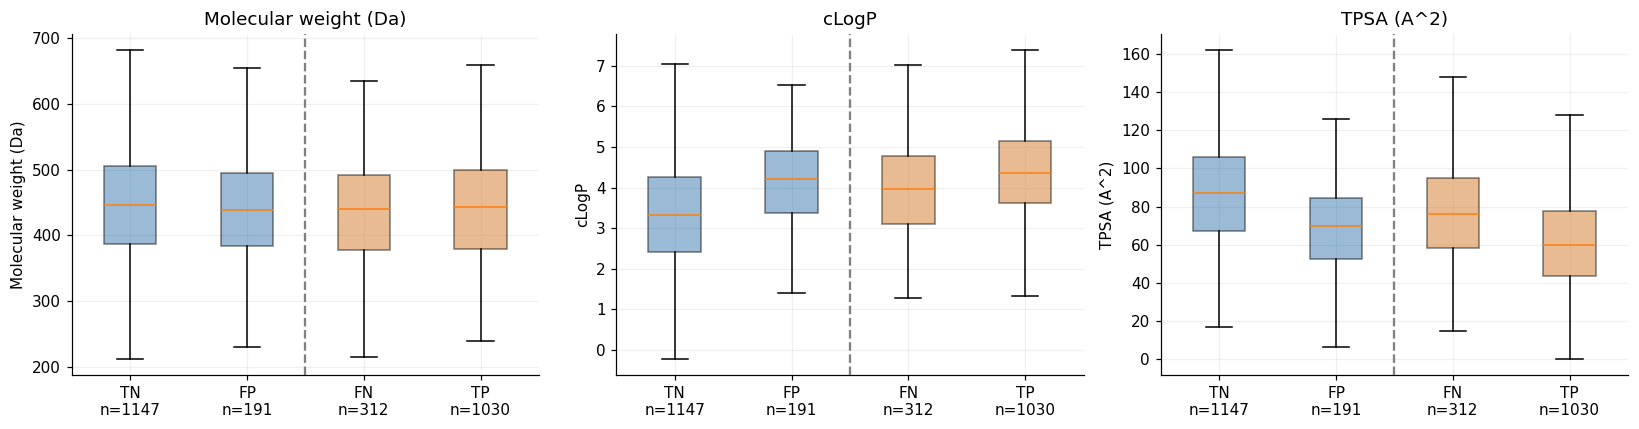

,Molecular weight (Da),cLogP,TPSA (A^2)
outcome,,,
TN,446.51,3.33,86.95
FP,438.59,4.22,69.87
FN,439.72,3.96,76.27
TP,443.42,4.36,59.98


In [5]:
properties = pd.DataFrame([calculate_descriptors(s) for s in results.smiles], index=results.index)
analysis = pd.concat([results, properties], axis=1)
selected = ["Molecular weight (Da)", "cLogP", "TPSA (A^2)"]
order = ["TN", "FP", "FN", "TP"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, prop in zip(axes, selected):
    values = [analysis.loc[analysis.outcome == group, prop].to_numpy() for group in order]
    boxes = ax.boxplot(values, labels=[f"{g}\nn={(analysis.outcome == g).sum()}" for g in order],
                       showfliers=False, patch_artist=True)
    for patch, color in zip(boxes["boxes"], [COLORS[0], COLORS[0], COLORS[1], COLORS[1]]):
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
    ax.axvline(2.5, color="gray", linestyle="--")
    ax.set(title=prop, ylabel=prop)
fig.tight_layout()
plt.show()
display(analysis.groupby("outcome")[selected].median().reindex(order).round(2))

### Ինչ ենք նկատում հատկությունների մեջ

Այս գործարկման FP-ների մեդիան cLogP-ն **4.22** է՝ TN-ների **3.33**-ի համեմատ, իսկ TPSA-ն՝ **69.87**՝ **86.95 Å²**-ի համեմատ։ Այսինքն՝ սխալ ահազանգ ստացած non-inhibitor-ները այս երկու հատկություններով մոտենում են ընդհանուր inhibitor խմբի նկարագրին։

Բաց թողնված inhibitor-ների (FN) TPSA մեդիանը **76.27 Å²** է, ճիշտ ճանաչվածների (TP)՝ **59.98 Å²**։ Սա վերլուծության ուղղություն է, ոչ մոդելի սխալի հաստատված պատճառ․ մոդելը սովորում է fingerprint-ներից։

## 6. Սխալ դասակարգված մոլեկուլների օրինակներ

Առաջին խմբում ցույց ենք տալիս ամենաբարձր score-ով FP-ները, երկրորդում՝ ամենացածր score-ով FN-ները։ Սրանք հատուկ ընտրված, ծայրահեղ սխալների օրինակներ են և **չեն ներկայացնում ամբողջ test set-ը**։ Մոդելը կարող է բարձր score-ով էլ սխալվել։ Պատկերը միայնակ չի բացատրում սխալի պատճառը․ հնարավոր են կառուցվածքի ներկայացման, ուսուցման տվյալների կամ պիտակների սահմանափակումներ։

### FP: 6 examples

,compound_id,row_index,label,prediction,score,smiles
1935,1658,9531,0,1,0.973333,CCc1nc2cc3c(cc2o1)CCN(CCCSc1nnc(-c2cccnc2)n1C)CC3
1367,4761,6824,0,1,0.953333,CC1=NC2C=C3CCN(CCCSc4nnc(-c5cccc6nc(C)ccc56)n4...
1911,854,9435,0,1,0.943333,Cn1c(SCCCN2CC[C@]3(C[C@@H]3c3ccc(C(F)(F)F)cc3)...
2145,9328,10432,0,1,0.943333,Cc1nc2ccc3c(c2s1)CCN(CCCSc1nnc(-c2ocnc2C)n1C)CC3
1955,2276,9596,0,1,0.938343,CN1CCC(c2nnc(SCCCN3CC[C@]4(C[C@@H]4c4ccc(C(F)(...
1670,10118,8235,0,1,0.936667,COc1ccc([C@H]2CN(CCCC3CCNCC3)C[C@@H]2CNC(=O)c2...


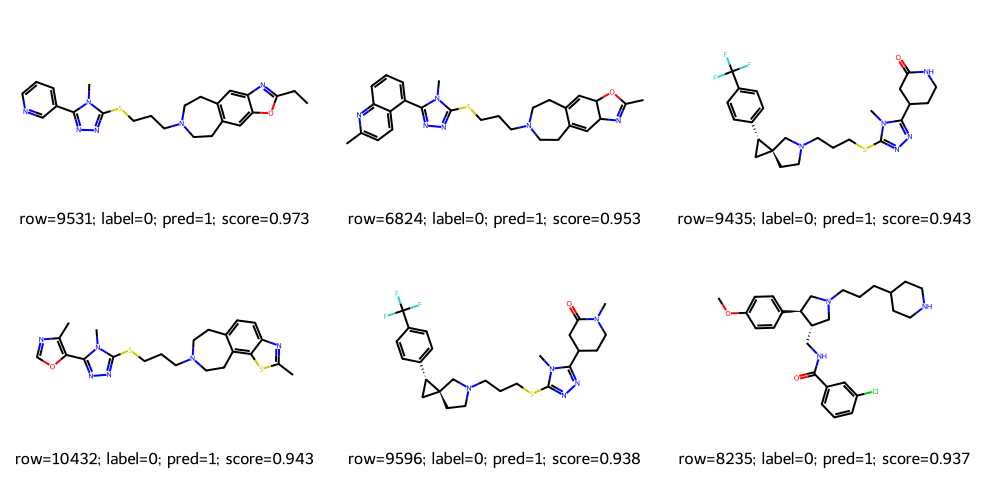

### FN: 6 examples

,compound_id,row_index,label,prediction,score,smiles
2330,1964,11331,1,0,0.030000,c1ccc(-c2ccccc2CC(c2cccnc2)c2cccnc2)cc1
2447,4730,12057,1,0,0.033333,COc1cc2nnc(C(N)=O)c(Nc3ccc(C)cc3F)c2cc1N1CCCN(...
1103,11326,5492,1,0,0.044983,O=C(c1ccc(Cl)cc1)N1CCN(c2ccc(OC3CCN(C4CCCC4)CC...
1544,10696,7702,1,0,0.046667,Cc1c[nH]c2c(Nc3nc(N[C@@H]4CCCC[C@H]4N)cc4cc[nH...
154,1439,686,1,0,0.046667,Cc1c[nH]c2c(Nc3nc(N[C@@H]4CCCC[C@@H]4N)cc4cc[n...
584,6010,2909,1,0,0.053365,O=C(c1cc(F)cc(F)c1)N1CCN(c2ccc(OC3CCN(C4CCCC4)...


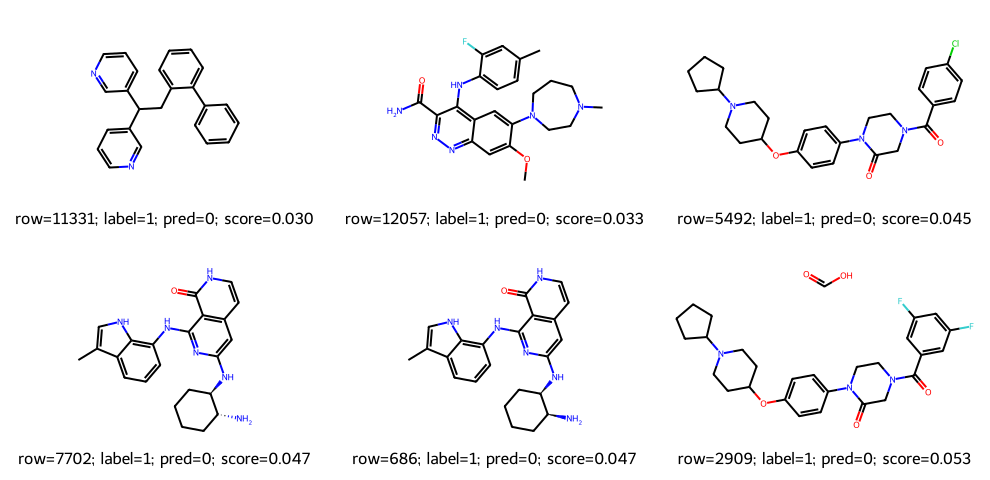

In [6]:
for outcome, ascending in [("FP", False), ("FN", True)]:
    examples = results[results.outcome == outcome].sort_values("score", ascending=ascending).head(6)
    display(Markdown(f"### {outcome}: {len(examples)} examples"))
    if examples.empty:
        display(Markdown("No examples in this category."))
        continue
    columns = [c for c in ["compound_id", "row_index", "label", "prediction", "score", "smiles"] if c in examples]
    display(examples[columns])
    legends = [f"row={row.row_index}; label={row.label}; pred={row.prediction}; score={row.score:.3f}"
               for row in examples.itertuples()]
    display(Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in examples.smiles],
        molsPerRow=3, subImgSize=(330, 240), legends=legends))

## 7. Ինչ պահել մտքում

- **FN և FP** տարբեր խնդիրներ են նկարագրում․ inhibitor բաց թողնել և կեղծ ահազանգ։
- **PR և ROC** կորերը նկարագրում են score-ների դասավորումը, ոչ փորձարարական հաստատումը կամ կալիբրացումը։
- Մոլեկուլների օրինակներն ու հատկությունների գրաֆիկները օգնում են հարցեր ձևակերպել, բայց պատճառ չեն ապացուցում։
- Այս test set-ը մեկ dataset-ի ներսում scaffold-ներով առանձնացված բաժին է, ոչ արտաքին վավերացում։
- Այս սխալներից ելնելով շեմ կամ մոդել փոխելու համար ընտրությունը պետք է անել training CV-ում և արդյունքը ստուգել նոր անկախ տվյալներով։